# Cloud Workload Forecasting: Azure VM trace

**Task:** i am to forecast the last 2 hours which is 24 steps of 5 minutes of two fleet-level numbers: how many VMs are running, and how busy their CPUs are on average. Then i am to say what an infrastructure team should do with the forecast.

**Models only two, on purpose:**
1. **Baseline: persistence.** "The next 2 hours will look like right now."
2. **Main model: damped-trend exponential smoothing (ETS).** A small statistical model that learns the recent level and trend, and lets the trend fade out.

**How you can run this notebook from scratch:** `pip install -e ".[dev]"`, put the dataset in `challenge_data/` (see the README), then *Kernel → Restart & Run All*. Everything is deterministic, so you get the same numbers every time. The same logic is available as one command: `python -m cwfc.predict --data challenge_data --output predictions.csv`.

**A simple map of this notebook**

| Part | What happens |
|---|---|
| 1-2 | Set up, load the data, check it is clean |
| 3 | Build the two time series, then lock away the last 24 points |
| 4 | Understand the workload (using only the training part) |
| 5-6 | How we test models without cheating, and the models themselves |
| 7-8 | Scores, and where the models go wrong |
| 9 | Choose a model and write `predictions.csv` |
| 10 | A simple capacity policy |
| 11 | One look at the locked-away data (final test) |
| 12 | Assumptions and limits |

## 1. Setup First

In [1]:
import os
import platform
import subprocess
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from IPython.display import Markdown, display

from cwfc.data import (TARGETS, TARGET_BOUNDS, build_targets, check_data_quality,
                       load_metadata, load_readings, split_train_holdout)
from cwfc.evaluate import (default_min_train, error_by_fold, error_by_step, interval_coverage,
                           rolling_origin_forecasts, score_table, select_model, DEFAULT_STEP)
from cwfc.metrics import mae, rmse
from cwfc.models import make_forecasters
from cwfc.policy import margin_tradeoff, smallest_margin_for_coverage
from cwfc.predict import forecast_holdout, holdout_scores, validate_predictions
from cwfc.validation import rolling_origin_train_sizes

np.random.seed(42)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = Path(os.environ.get("CWFC_DATA", ROOT / "challenge_data"))
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

HORIZON = 24  # the holdout is the final 24 five-minute steps = 2 hours

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=130, bbox_inches="tight")

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| statsmodels", statsmodels.__version__)
print("data folder:", DATA_DIR)

python 3.14.3 | numpy 2.5.4 | pandas 3.1.0 | statsmodels 0.15.0
data folder: C:\Users\HP\Desktop\atomity-forecasting\challenge_data


## 2. Loading the data and to check if it is clean

The file has one row per VM per 5-minute step: the VM's `min_cpu`, `max_cpu` and `avg_cpu` during those 5 minutes. Before modelling anything lets check cadence, gaps, duplicates and missing values, because a quiet data problem can ruin a forecast.

In [2]:
readings = load_readings(DATA_DIR)
meta = load_metadata(DATA_DIR)

print("readings:", readings.shape, "| metadata:", meta.shape)
readings.head()

readings: (1340000, 5) | metadata: (10000, 11)


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [3]:
quality = check_data_quality(readings)
pd.Series(quality, name="value").to_frame()

,value
rows,1340000
vms,10000
timestamps,134
first_timestamp,0
last_timestamp,39900
step_seconds_seen,{300: 133}
irregular_steps,0
duplicate_vm_timestamp_rows,0
missing_avg_cpu,0
avg_cpu_outside_0_100,0


* The time step is exactly 300 seconds (5 minutes) everywhere, with no gaps, so i can treat the index as a clean grid and need **no resampling**.
* No duplicate (VM, time) rows, no missing `avg_cpu`, nothing outside 0-100.
* Every VM has the same number of readings, so there are no half-observed VMs.

## 3. Now Building the two target series, then lock away the last 24 points

The two things we forecast, at every 5-minute step:

* `active_vm_count`: how many different VMs have a valid reading.
* `aggregate_cpu_utilization`: the average of all VMs' `avg_cpu`, as a percentage.

**Rule order matters for avoiding leakage:** we first build the full series, this uses only the raw readings, and only then cut it into **110 training points** and **24 holdout points**. After the cut, nothing we fit, tune or choose may look at the holdout values. The holdout timestamps are the only thing we use from that part, because we have to say which times we are predicting.

In [4]:
targets = build_targets(readings)
train, holdout = split_train_holdout(targets, HORIZON)

print(f"full series: {len(targets)} steps | training: {len(train)} | holdout: {len(holdout)}")
print(f"training covers t = {train.index.min()}..{train.index.max()} s  ({len(train) * 5 / 60:.1f} hours)")
print(f"holdout times to predict: t = {holdout.index.min()}..{holdout.index.max()} s  (values stay hidden until Part 11)")
train.head()

full series: 134 steps | training: 110 | holdout: 24
training covers t = 0..32700 s  (9.2 hours)
holdout times to predict: t = 33000..39900 s  (values stay hidden until Part 11)


,active_vm_count,aggregate_cpu_utilization
timestamp,,
0,10000.0,9.396898
300,10000.0,9.353775
600,10000.0,9.454383
900,10000.0,9.224419
1200,10000.0,9.143503


## 4. Lets Understand the workload

From here on we look **only at the 110 training steps**. That way nothing we learn or decide can be influenced by the holdout.

In [5]:
# VM-level readings inside the training window, with each VM's category and size attached
vm_info = meta.set_index("vm_id")[["vm_category", "virtual_core_bucket", "memory_gb_bucket"]].astype(str)
tr = readings[readings["timestamp"].isin(train.index)].join(vm_info, on="vm_id")
tr["hour"] = tr["timestamp"] / 3600
print(len(tr), "VM readings in the training window")

1100000 VM readings in the training window


### 4.1 Lets see how many VMs are running, and do VMs come and go?

In [6]:
print(train["active_vm_count"].describe().round(1).to_string())

# Metadata lifetimes are used here only to DESCRIBE churn, never as model inputs.
first_t, last_t = targets.index.min(), targets.index.max()
print("\nVMs created at or before the first timestamp:", f"{(meta['timestamp_vm_created'] <= first_t).mean():.0%}")
print("VMs deleted before the last timestamp:       ", f"{(meta['timestamp_vm_deleted'] <= last_t).mean():.0%}")

count      110.0
mean     10000.0
std          0.0
min      10000.0
25%      10000.0
50%      10000.0
75%      10000.0
max      10000.0

VMs created at or before the first timestamp: 100%
VMs deleted before the last timestamp:        0%


**this matters becuase** `active_vm_count` is exactly the same number at every step. All VMs were created before the window starts and none is deleted during it, so there is **zero churn** in this release. That target has no variation to forecast: the right answer is "the same number as now", and persistence gets it exactly right. We still run both models on it (Part 7) to show that, and the code handles a fleet that does change (tested on fake data).

The interesting forecasting problem is therefore the CPU line.

### 4.2 How busy are the VMs?

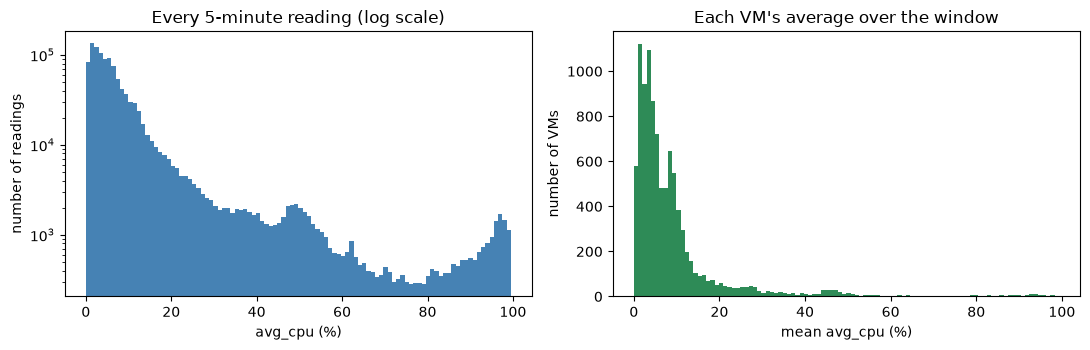

avg_cpu quantiles (%): {0.1: 1.23, 0.5: 5.12, 0.9: 19.69, 0.95: 37.29, 0.99: 87.41}
VMs averaging under 5% CPU: 46.4% | averaging over 50%: 2.2%
VMs that touched 90%+ CPU at least once: 17.1%
Share of all CPU use that comes from the busiest 1% of VMs: 9.6%


In [7]:
per_vm_mean = tr.groupby("vm_id")["avg_cpu"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(tr["avg_cpu"], bins=100, log=True, color="steelblue")
axes[0].set(title="Every 5-minute reading (log scale)", xlabel="avg_cpu (%)", ylabel="number of readings")
axes[1].hist(per_vm_mean, bins=100, color="seagreen")
axes[1].set(title="Each VM's average over the window", xlabel="mean avg_cpu (%)", ylabel="number of VMs")
fig.tight_layout()
save(fig, "01_cpu_distributions.png")
plt.show()

quantiles = tr["avg_cpu"].quantile([0.10, 0.50, 0.90, 0.95, 0.99]).round(2)
print("avg_cpu quantiles (%):", quantiles.to_dict())
share_low = (per_vm_mean < 5).mean()
share_hot = (per_vm_mean > 50).mean()
ever_hot = (tr.groupby("vm_id")["max_cpu"].max() > 90).mean()
top1 = per_vm_mean.sort_values(ascending=False).head(len(per_vm_mean) // 100).sum() / per_vm_mean.sum()
print(f"VMs averaging under 5% CPU: {share_low:.1%} | averaging over 50%: {share_hot:.1%}")
print(f"VMs that touched 90%+ CPU at least once: {ever_hot:.1%}")
print(f"Share of all CPU use that comes from the busiest 1% of VMs: {top1:.1%}")

close to half the VMs average under about 5% CPU, a small group is very busy, and the readings have a long tail. That is the classic shape of cloud over-provisioning: lots of paid-for capacity sitting unused, while a few hot VMs need protecting. It also means the **fleet average is dominated by the many quiet VMs**, which is why the average moves so little.

### 4.3 Now What does the fleet-average CPU do over time?

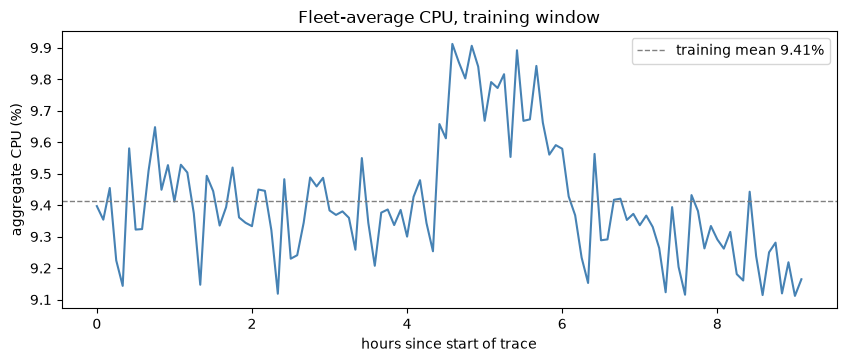

mean 9.414% | std 0.194 | min 9.112 | max 9.912
typical 5-minute change (std of step-to-step difference): 0.158 points
lag-1 autocorrelation of the level: 0.67


,hour 0,hour 1,hour 2,hour 3,hour 4,hour 5,hour 6,hour 7,hour 8,hour 9
mean CPU %,9.411,9.405,9.367,9.361,9.616,9.707,9.372,9.295,9.239,9.138


In [8]:
y_train = train["aggregate_cpu_utilization"]
hours = train.index / 3600

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(hours, y_train, color="steelblue", lw=1.5)
ax.axhline(y_train.mean(), color="grey", ls="--", lw=1, label=f"training mean {y_train.mean():.2f}%")
ax.set(title="Fleet-average CPU, training window", xlabel="hours since start of trace", ylabel="aggregate CPU (%)")
ax.legend()
save(fig, "02_fleet_cpu_training.png")
plt.show()

print(f"mean {y_train.mean():.3f}% | std {y_train.std():.3f} | min {y_train.min():.3f} | max {y_train.max():.3f}")
print(f"typical 5-minute change (std of step-to-step difference): {y_train.diff().std():.3f} points")
print(f"lag-1 autocorrelation of the level: {y_train.autocorr(1):.2f}")

# average per hour-long block (12 steps) to see slower movements
blocks = (np.arange(len(y_train)) // 12)
hourly = y_train.groupby(blocks).mean().rename("mean CPU %")
hourly.index = [f"hour {i}" for i in hourly.index]
hourly.round(3).to_frame().T

### 4.4 Lets see if different kinds of VM behave differently?

,vms,mean_cpu,std_cpu,p95_cpu
vm_category,,,,
Delay-insensitive,6180,8.26,12.04,25.94
Interactive,3091,11.51,16.95,49.15
Unknown,729,10.35,17.84,52.50


,vms,mean_cpu,std_cpu
virtual_core_bucket,,,
2,7534,9.76,14.58
4,1908,7.92,13.32
8,486,9.66,12.49
24,62,11.43,16.34
>24,10,6.62,8.61


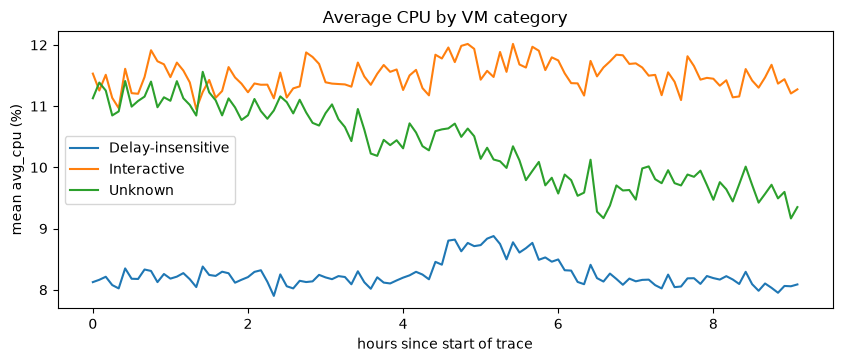

change in mean CPU during the hump vs before it, by category (points):
vm_category
Delay-insensitive    0.475
Interactive          0.340
Unknown             -0.691


In [9]:
by_cat = tr.groupby("vm_category").agg(vms=("vm_id", "nunique"), mean_cpu=("avg_cpu", "mean"),
                                       std_cpu=("avg_cpu", "std"), p95_cpu=("avg_cpu", lambda s: s.quantile(.95)))
by_cores = tr.groupby("virtual_core_bucket").agg(vms=("vm_id", "nunique"), mean_cpu=("avg_cpu", "mean"),
                                                 std_cpu=("avg_cpu", "std"))
order = [c for c in ["2", "4", "8", "24", ">24"] if c in by_cores.index]
display(by_cat.round(2))
display(by_cores.loc[order].round(2))

cat_series = tr.groupby(["timestamp", "vm_category"])["avg_cpu"].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 3.6))
for name in cat_series.columns:
    ax.plot(cat_series.index / 3600, cat_series[name], label=name)
ax.set(title="Average CPU by VM category", xlabel="hours since start of trace", ylabel="mean avg_cpu (%)")
ax.legend()
save(fig, "03_cpu_by_category.png")
plt.show()

# how much of the fleet-level hump comes from each category?  (hump window = 54..72, found in 4.3)
hump = slice(54, 73)
shift = cat_series.iloc[hump].mean() - cat_series.iloc[:54].mean()
print("change in mean CPU during the hump vs before it, by category (points):")
print(shift.round(3).to_string())

**What we see**

* **Interactive** VMs (user-facing) run hotter on average and are much more spread out (high standard deviation) than **Delay-insensitive** (batch-style) VMs.
* Small 2-core VMs are the vast majority (about three quarters of the fleet), so they dominate the fleet average.
* The hump is **not one category misbehaving**. The two big categories rise together during it (the batch-style group most clearly, around hours 4.5 to 6), while the small "Unknown" group drifts steadily downward through the whole window and partly offsets them. A fleet-wide shift made of several groups moving at once is hard to forecast from the average alone.

**Why this matters operationally:** a capacity rule should not treat all VMs the same. Interactive VMs deserve more headroom than batch VMs, and a forecast of the average says nothing about whether a few big VMs are about to run hot.

### 4.5 Peaks and quiet periods

In [10]:
peaks = y_train.nlargest(5).rename("highest").reset_index()
lows = y_train.nsmallest(5).rename("lowest").reset_index()
peaks["hour"] = (peaks["timestamp"] / 3600).round(2)
lows["hour"] = (lows["timestamp"] / 3600).round(2)
display(pd.concat([peaks[["hour", "highest"]], lows[["hour", "lowest"]]], axis=1).round(3))

,hour,highest,hour,lowest
0,4.58,9.912,9.00,9.112
1,4.83,9.906,8.58,9.114
2,5.42,9.892,7.58,9.115
3,4.67,9.854,2.33,9.118
4,5.67,9.842,8.83,9.120


The five highest fleet-average readings all sit inside the hump (roughly hours 4.5 to 5.7), and four of the five lowest come in the last two hours, after the drop. So peaks here are **sustained shifts**, not one-off spikes. That matters for the policy in Part 10: a single reading is a poor guide to what the next hour holds, but the level in the last few minutes is a good guide.

**Summary of what the workload looks like:** a big, stable fleet; mostly idle VMs with a hot tail; a very smooth average that makes one gentle hump; no churn; not enough history to see daily patterns.

## 5. How we test models without cheating

We never shuffle time-series rows into train and test, because that lets the model "see the future". Instead we use **rolling-origin evaluation**:

1. Pretend it is time *T*. Give the model only the data up to *T*.
2. Ask for the next 24 steps. Compare with what really happened.
3. Move *T* forward by 4 steps and repeat.

This copies the real job: a team will always forecast the next 2 hours from the history they have *so far*.

The very first fold trains on 60 points (5 hours), enough for ETS to learn something. The last fold has to leave room for 24 steps, so we get **7 folds** from our 110 training points. All of this happens **inside the training window**; the 24 holdout points are not touched.

A step is called a **peak step** when the actual value is at or above the 75th percentile of *that fold's own training data*. The label uses only the past.

training sizes per fold: [60, 64, 68, 72, 76, 80, 84]


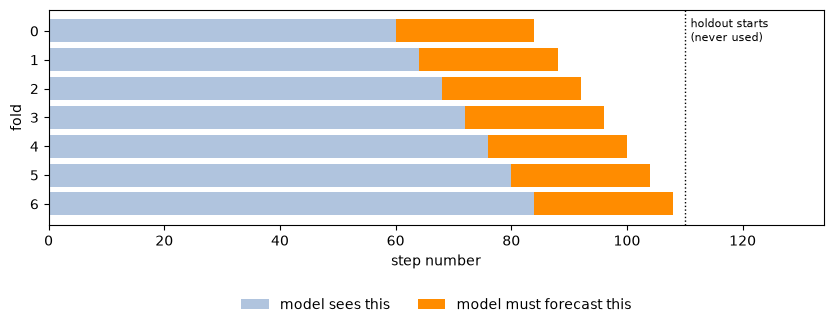

In [11]:
MIN_TRAIN = default_min_train(len(train), HORIZON, DEFAULT_STEP)   # 60 for our 110-point window
sizes = rolling_origin_train_sizes(len(train), HORIZON, MIN_TRAIN, DEFAULT_STEP)
print("training sizes per fold:", sizes)

fig, ax = plt.subplots(figsize=(10, 2.8))
for i, n in enumerate(sizes):
    ax.barh(i, n, color="lightsteelblue", label="model sees this" if i == 0 else None)
    ax.barh(i, HORIZON, left=n, color="darkorange", label="model must forecast this" if i == 0 else None)
ax.axvline(len(train), color="black", ls=":", lw=1)
ax.text(len(train) + 1, 0, "holdout starts\n(never used)", fontsize=8, va="center")
ax.set(xlabel="step number", ylabel="fold", xlim=(0, len(targets)), yticks=range(len(sizes)))
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, frameon=False)
save(fig, "04_validation_folds.png")
plt.show()

## 6. The two models

**Persistence (baseline).** Predict that all 24 future values equal the last one we saw. It sounds silly, but for a slow-moving series it is often very hard to beat, and every fancier model must prove it can do better.

**Damped-trend ETS (main model).** ETS stands for *error, trend, seasonality*. We use it as "level + trend": it keeps a smoothed estimate of where the series is now and which way it is drifting. *Damped* means the drift fades out over the next steps instead of continuing forever, which is safer for a 2-hour forecast. It also produces a **prediction interval** (a likely range), which we use in the capacity policy. We cannot add a seasonal part because we have no full cycle to learn from.

Both models are in `src/cwfc/models.py`. Each one only receives the past values it is given, and a unit test proves a forecast does not change if you change anything after the cut-off.

In [12]:
val = {}
for target in TARGETS:
    forecasters = make_forecasters(TARGET_BOUNDS[target])
    results = rolling_origin_forecasts(train[target].to_numpy(), forecasters, HORIZON, MIN_TRAIN, DEFAULT_STEP)
    val[target] = {"results": results, "scores": score_table(results)}

# Make sure ETS really ran (it silently falls back to persistence on constant data):
for target in TARGETS:
    methods = val[target]["results"].query("model == 'damped_ets'")["method"].value_counts()
    print(target, "->", methods.to_dict())

active_vm_count -> {'persistence (ets fallback: too short or constant)': 168}
aggregate_cpu_utilization -> {'damped_ets': 168}


## 7. how good are the forecasts?

i am to report several metrics below:

* **MAE**: average size of the miss, in the same units as the target (CPU percentage points).
* **RMSE**: like MAE but punishes big misses more.
* **sMAPE**: a percentage error. It divides by |actual| + |forecast| and has a floor of 1e-8, so a near-zero value can never make it explode.
* **MAE ratio vs baseline**: model MAE divided by persistence MAE. Below 1.0 means better than the baseline; improvement % = (1 − ratio) × 100.
* **peak MAE**: MAE on the peak steps only.

In [13]:
cols = ["MAE", "RMSE", "sMAPE_%", "peak_MAE", "MAE_ratio", "improvement_%", "peak_MAE_ratio", "folds", "points"]
display(Markdown("**CPU: `aggregate_cpu_utilization`** (7 folds x 24 steps = 168 forecast points per model)"))
display(val["aggregate_cpu_utilization"]["scores"][cols].round(4))
display(Markdown("**VM count: `active_vm_count`**"))
display(val["active_vm_count"]["scores"][cols].round(4))

**CPU: `aggregate_cpu_utilization`** (7 folds x 24 steps = 168 forecast points per model)

,MAE,RMSE,sMAPE_%,peak_MAE,MAE_ratio,improvement_%,peak_MAE_ratio,folds,points
model,,,,,,,,,
persistence,0.2194,0.2745,2.3118,0.1533,1.0000,0.0000,1.000,7,168
damped_ets,0.2390,0.3002,2.5111,0.1858,1.0893,-8.9273,1.212,7,168


**VM count: `active_vm_count`**

,MAE,RMSE,sMAPE_%,peak_MAE,MAE_ratio,improvement_%,peak_MAE_ratio,folds,points
model,,,,,,,,,
persistence,0.0,0.0,0.0,0.0,NaN,NaN,NaN,7,168
damped_ets,0.0,0.0,0.0,0.0,NaN,NaN,NaN,7,168


**Reading the table**

* **CPU:** persistence beats damped ETS on every headline metric (MAE, RMSE, sMAPE) and also on the peak steps. The ETS model is roughly 9% worse than the baseline on MAE. The "improvement %" is negative: the main model did **not** beat the simple baseline.
* **VM count:** both models have zero error, because the count never changes. The "ratio vs baseline" is 0 ÷ 0, which is undefined, so it shows as `NaN` instead of a made-up number.

That is a legitimate result, not a failure of the project: the brief says a simple, well-validated baseline can be the right answer. We report it as it is and do not tune ETS until it wins.

## 8. Where the models go wrong, and why

In [14]:
cpu = val["aggregate_cpu_utilization"]["results"]
y_cpu = train["aggregate_cpu_utilization"].to_numpy()

# For each fold: how much did the real series move (max minus min) inside the 24 steps to forecast?
fold_table = error_by_fold(cpu).copy()
fold_table["n_train"] = sizes
fold_table["window_range"] = [np.ptp(y_cpu[n:n + HORIZON]) for n in sizes]
fold_table = fold_table[["n_train", "window_range", "persistence", "damped_ets"]]
display(fold_table.round(3))
corr = fold_table["window_range"].corr(fold_table["persistence"])
print(f"correlation between how much the series moved in the window and persistence error: {corr:.2f}")

model,n_train,window_range,persistence,damped_ets
fold,,,,
0,60,0.739,0.305,0.378
1,64,0.739,0.358,0.360
2,68,0.727,0.301,0.336
3,72,0.464,0.257,0.301
4,76,0.447,0.110,0.097
5,80,0.328,0.087,0.086
6,84,0.328,0.118,0.115


correlation between how much the series moved in the window and persistence error: 0.92


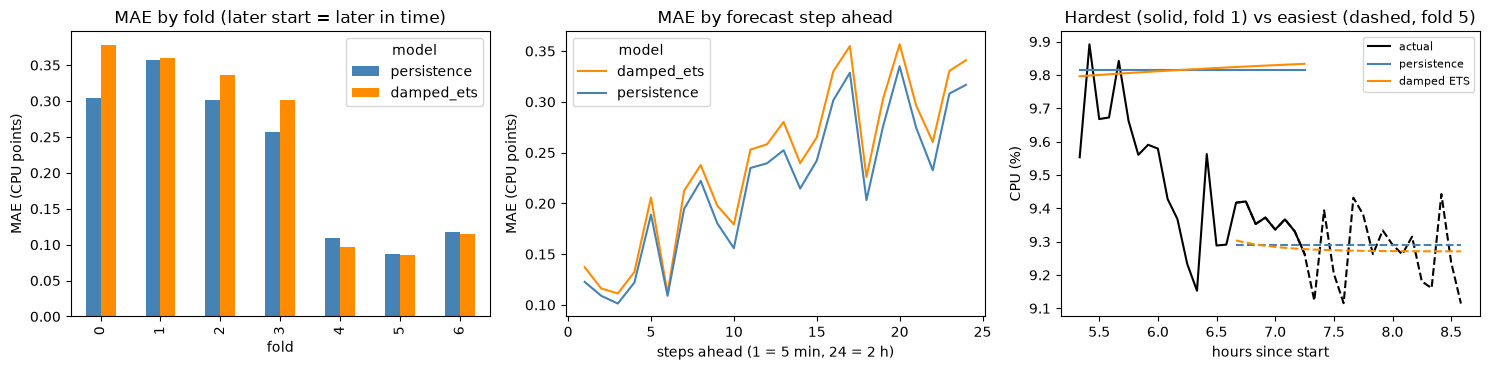

90% prediction interval of ETS contained the real value 78% of the time (target: 90%)
average signed error by model (CPU points): {'damped_ets': 0.1975, 'persistence': 0.1737}


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

# (a) error by fold
fold_table[["persistence", "damped_ets"]].plot.bar(ax=axes[0], color=["steelblue", "darkorange"])
axes[0].set(title="MAE by fold (later start = later in time)", xlabel="fold", ylabel="MAE (CPU points)")

# (b) error by how far ahead we forecast
by_step = error_by_step(cpu)
by_step.plot(ax=axes[1], color=["darkorange", "steelblue"])
axes[1].set(title="MAE by forecast step ahead", xlabel="steps ahead (1 = 5 min, 24 = 2 h)", ylabel="MAE (CPU points)")

# (c) hardest and easiest fold, both models against what actually happened
hard = int(fold_table["persistence"].idxmax())
easy = int(fold_table["persistence"].idxmin())
for fold, ls in [(hard, "-"), (easy, "--")]:
    g = cpu[cpu["fold"] == fold]
    pos = g["position"].unique() * 300 / 3600
    first = (fold == hard)  # label each line type once so the legend stays short
    axes[2].plot(pos, g[g.model == "persistence"]["actual"], color="black", ls=ls, label="actual" if first else None)
    axes[2].plot(pos, g[g.model == "persistence"]["forecast"], color="steelblue", ls=ls, label="persistence" if first else None)
    axes[2].plot(pos, g[g.model == "damped_ets"]["forecast"], color="darkorange", ls=ls, label="damped ETS" if first else None)
axes[2].set(title=f"Hardest (solid, fold {hard}) vs easiest (dashed, fold {easy})",
            xlabel="hours since start", ylabel="CPU (%)")
axes[2].legend(fontsize=8)
fig.tight_layout()
save(fig, "05_error_analysis.png")
plt.show()

print(f"90% prediction interval of ETS contained the real value {interval_coverage(cpu):.0f}% of the time (target: 90%)")

# Average signed error (forecast minus actual): above 0 = forecasts run high, below 0 = run low
bias = (cpu.assign(error=cpu["forecast"] - cpu["actual"]).groupby("model")["error"].mean()).round(4)
print("average signed error by model (CPU points):", bias.to_dict())

**What the numbers show**

1. **Errors follow movement, not just model quality.** The early folds (where the 24-step window covers the hump rising and falling) have about three times the error of the late, calm folds, and the table shows those same folds have the widest ups and downs inside their window. The bigger the move, the bigger the miss, for *both* models. Neither model has any information that says "a hump is coming", because it comes from many VMs changing at once.
2. **Errors grow with distance.** Looking 2 hours ahead is harder than 5 minutes ahead, as expected, but even the 24th step is off by only about 0.3 CPU points.
3. **ETS loses in the turbulent folds and ties in the calm ones.** In folds 0-3 (the hump) ETS is worse; in the calm folds 4-6 it is about equal or marginally better. That pattern fits the idea that ETS's trend term keeps leaning in the old direction right after the series turns, while persistence catches the new level one step later. We cannot prove the mechanism from 7 folds. The bias line above also shows both models forecast a little too high on average (the series drifted down after the hump), ETS slightly more so.
4. **ETS's 90% interval is too narrow.** It covered the true value only about 78% of the time instead of 90%, again because of the level shifts. We must not trust it as a safety band without adding a margin (see Part 10).
5. **Near-zero denominators.** Our percentage error (sMAPE) is protected by a floor, and the CPU values are around 9%, nowhere near zero, so it is stable here.

**Limit of the evidence:** 7 folds that overlap heavily on 110 points is a small sample, so treat the 9% gap as "persistence is at least as good", not as a precise number.

## 9. Now lets choose our model and write `predictions.csv`out

In [ ]:
for target in TARGETS:
    chosen, scores, _ = select_model(train[target].to_numpy(), HORIZON, TARGET_BOUNDS[target], MIN_TRAIN, DEFAULT_STEP)
    print(f"{target:28s} -> {chosen}")

active_vm_count              -> persistence
aggregate_cpu_utilization    -> persistence


In [16]:
# Fit the chosen models on the 110 training points only and forecast the 24 holdout timestamps.
predictions, info = forecast_holdout(targets, HORIZON)
validate_predictions(predictions, holdout.index.to_numpy())   # checks every rule in SUBMISSION.md

predictions.to_csv(ROOT / "predictions.csv", index=False)
print("saved", ROOT / "predictions.csv", "|", len(predictions), "rows")
predictions.head(24)

saved C:\Users\HP\Desktop\atomity-forecasting\predictions.csv | 24 rows


,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000.0,9.164556
1,33300,10000.0,9.164556
2,33600,10000.0,9.164556
3,33900,10000.0,9.164556
4,34200,10000.0,9.164556
5,34500,10000.0,9.164556
6,34800,10000.0,9.164556
7,35100,10000.0,9.164556
8,35400,10000.0,9.164556
9,35700,10000.0,9.164556


In [ ]:
# Reproducibility check: the command-line tool must give exactly the same file.
with tempfile.TemporaryDirectory() as tmp:
    out = Path(tmp) / "cli_predictions.csv"
    subprocess.run([sys.executable, "-m", "cwfc.predict", "--data", str(DATA_DIR), "--output", str(out)],
                   check=True, capture_output=True)
    cli = pd.read_csv(out)
same = np.array_equal(cli["timestamp"], predictions["timestamp"]) and np.allclose(
    cli[list(TARGETS)].to_numpy(), predictions[list(TARGETS)].to_numpy())
print("command-line output identical to the notebook's predictions:", same)

command-line output identical to the notebook's predictions: True


## 10. What should an infrastructure team do with the forecast?

**The decision:** how much CPU capacity to plan for over the next 2 hours.

* **Under-provisioning** (planning too little): real demand lands above the plan. Slowdowns, throttling, failed scale-ups. Costly but rare.
* **Over-provisioning** (planning too much): paying for capacity nobody uses. A small, steady cost.

**Simple policy:** *plan for* `forecast x (1 + margin)`. The only knob is the margin, and we choose it from evidence: replay the policy on the 7 validation folds and count how often the plan was high enough ("covered") and how much spare room it carried. We try two ways of building the plan: persistence plus a margin, and the ETS **upper band** (the top of its 90% interval) plus a margin.

**Plan = persistence forecast x (1 + margin)**   (units: CPU percentage points; fleet average is about 9.4)

,covered_%,avg_spare_pts,avg_spare_%_of_actual,avg_shortfall_pts,worst_shortfall_pts
margin_%,,,,,
0.0,75.595,0.197,2.109,0.023,0.329
1.0,89.286,0.275,2.951,0.006,0.237
2.0,98.214,0.366,3.914,0.001,0.145
3.0,99.405,0.460,4.926,0.000,0.052
5.0,100.000,0.651,6.960,0.000,0.000
7.5,100.000,0.890,9.507,0.000,0.000
10.0,100.000,1.128,12.053,0.000,0.000
20.0,100.000,2.083,22.240,0.000,0.000


**Plan = ETS upper band x (1 + margin)**

,covered_%,avg_spare_pts,avg_spare_%_of_actual,avg_shortfall_pts,worst_shortfall_pts
margin_%,,,,,
0.0,100.0,0.605,6.476,0.0,0.0
1.0,100.0,0.705,7.541,0.0,0.0
2.0,100.0,0.804,8.606,0.0,0.0
3.0,100.0,0.904,9.670,0.0,0.0
5.0,100.0,1.104,11.800,0.0,0.0
7.5,100.0,1.353,14.462,0.0,0.0
10.0,100.0,1.602,17.124,0.0,0.0
20.0,100.0,2.600,27.771,0.0,0.0


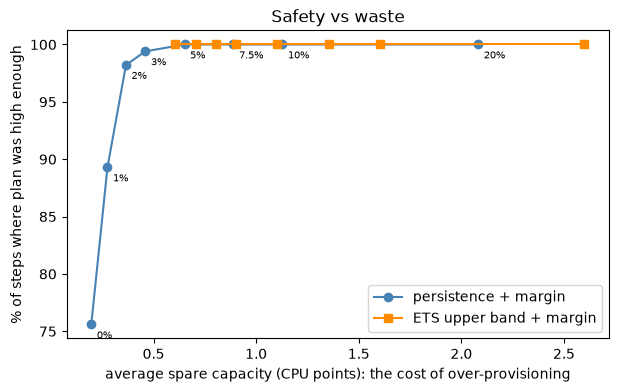

persistence + margin: >=99% covered needs 3% margin; zero shortfalls in any fold needs 5%


In [17]:
margins = (0.0, 0.01, 0.02, 0.03, 0.05, 0.075, 0.10, 0.20)
plan_persist = margin_tradeoff(cpu, "persistence", basis="forecast", margins=margins)
plan_ets = margin_tradeoff(cpu, "damped_ets", basis="upper", margins=margins)

display(Markdown("**Plan = persistence forecast x (1 + margin)**   (units: CPU percentage points; fleet average is about 9.4)"))
display(plan_persist.round(3))
display(Markdown("**Plan = ETS upper band x (1 + margin)**"))
display(plan_ets.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(plan_persist["avg_spare_pts"], plan_persist["covered_%"], "o-", color="steelblue", label="persistence + margin")
ax.plot(plan_ets["avg_spare_pts"], plan_ets["covered_%"], "s-", color="darkorange", label="ETS upper band + margin")
for m, row in plan_persist.iterrows():
    ax.annotate(f"{m:g}%", (row["avg_spare_pts"], row["covered_%"]), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax.set(xlabel="average spare capacity (CPU points): the cost of over-provisioning",
       ylabel="% of steps where plan was high enough", title="Safety vs waste")
ax.legend()
save(fig, "06_policy_tradeoff.png")
plt.show()

m99 = smallest_margin_for_coverage(plan_persist, 99.0)
m100 = smallest_margin_for_coverage(plan_persist, 100.0)
print(f"persistence + margin: >=99% covered needs {m99:g}% margin; zero shortfalls in any fold needs {m100:g}%")

**Reading it**

* With **no margin**, persistence is high enough only about 3 steps in 4, so a plain forecast is not a safe plan: about a quarter of the time demand lands above it.
* A **small margin fixes this cheaply**. With +3% the plan is high enough 99% of the time; with +5% it was high enough in every step of every fold. At +5% the spare room is only about 0.65 CPU points (the fleet averages about 9.4%).
* The **ETS upper band** reaches full coverage with no extra margin and about the same spare room (about 0.60 points), so the two ways of planning are close. We prefer the persistence rule because it is simpler and needs no model fit. The band is also only this safe because every miss in this window happened on the *downside* (the 90% interval's low side), which is not guaranteed to repeat.

### Recommended policy

1. **Plan for** `latest fleet-average CPU x 1.05` over the next 2 hours, re-computed every 5 minutes as new readings arrive. Use **+3%** if cost matters more than avoiding any shortfall, and **+10%** if slowdowns are expensive. The trade-off table above is the evidence for each choice.
2. **Alert when the live fleet average moves more than about 0.5 points away from the value the plan was built on** (about 5% of the average). The errors in Part 8 came from sustained shifts, so a big move is the signal to re-plan immediately instead of waiting.
3. **Segment rule:** keep extra per-VM headroom for **Interactive** VMs (hotter and much more variable, Part 4.4) and be relaxed with Delay-insensitive ones. The fleet average hides a hot tail: a few percent of VMs average over 50% and a sixth of VMs touch 90%+ at some point (Part 4.2). Those need their own per-VM or per-segment rule; the fleet average cannot protect them.
4. **Fleet-wide, the average CPU is only about 9%.** The bigger money question is rightsizing: much of the fleet is idle capacity.
5. **VM count:** plan for "the same number as now" and watch it. It has not changed in this window, but the same policy works if deployments start adding or removing VMs.

**Honest caveat:** the margin was chosen on the same 7 folds it was scored on, and the validation window contains only one hump. A bigger shift than any seen in these 9 hours could still exceed a 5% margin. Part 11 gives one out-of-sample check, and in production the margin should be re-checked as more data arrives.

## 11. Final test: one look at the holdout

Everything above is finished and locked. Only now do we open the 24 held-out values and score what we already decided. This is **reporting, not tuning**: nothing earlier in the notebook used these numbers, and if you re-run the notebook the choice does not change.

In [18]:
actual = holdout[list(TARGETS)]
final = holdout_scores(targets, predictions, HORIZON)
display(Markdown("**Submitted predictions vs persistence baseline, on the real holdout**"))
display(final.round(4))

# For information only: the other model on the same holdout (it was NOT chosen with this).
train_cpu = train["aggregate_cpu_utilization"].to_numpy()
ets_fc = make_forecasters(TARGET_BOUNDS["aggregate_cpu_utilization"])["damped_ets"](train_cpu, HORIZON).mean
act_cpu = actual["aggregate_cpu_utilization"].to_numpy()
print(f"for reference, damped ETS on the holdout (not chosen with this): MAE {mae(act_cpu, ets_fc):.4f}, RMSE {rmse(act_cpu, ets_fc):.4f}")

# Did the recommended policy (plan = last value x 1.05) hold up on data it never saw?
plan = train_cpu[-1] * 1.05
spare = plan - act_cpu
print(f"policy check: plan = {plan:.3f}%  | covered in {(spare >= 0).mean():.0%} of the 24 steps"
      f" | average spare {spare.clip(min=0).mean():.3f} pts | worst shortfall {(-spare).clip(min=0).max():.3f} pts")

**Submitted predictions vs persistence baseline, on the real holdout**

,model_MAE,model_RMSE,baseline_MAE,baseline_RMSE
target,,,,
active_vm_count,0.0000,0.0000,0.0000,0.0000
aggregate_cpu_utilization,0.1468,0.1848,0.1468,0.1848


for reference, damped ETS on the holdout (not chosen with this): MAE 0.1567, RMSE 0.1941
policy check: plan = 9.623%  | covered in 96% of the 24 steps | average spare 0.354 pts | worst shortfall 0.013 pts


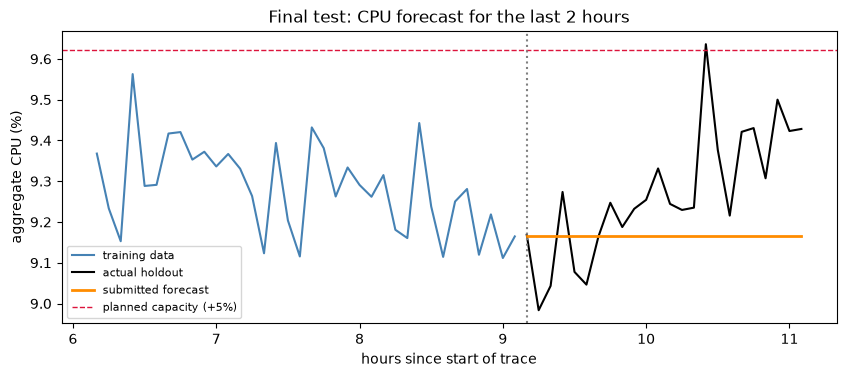

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.8))
last = 36  # show the last 3 hours of training for context
ax.plot(train.index[-last:] / 3600, train_cpu[-last:], color="steelblue", label="training data")
ax.plot(holdout.index / 3600, act_cpu, color="black", label="actual holdout")
ax.plot(holdout.index / 3600, predictions["aggregate_cpu_utilization"], color="darkorange", lw=2, label="submitted forecast")
ax.axhline(plan, color="crimson", ls="--", lw=1, label="planned capacity (+5%)")
ax.axvline(holdout.index.min() / 3600, color="grey", ls=":")
ax.set(title="Final test: CPU forecast for the last 2 hours", xlabel="hours since start of trace", ylabel="aggregate CPU (%)")
ax.legend(fontsize=8)
save(fig, "07_final_forecast.png")
plt.show()

**How to read the final test.** The submitted forecast is the chosen baseline, so it is a flat line at the last training value. Its holdout error (about 0.15 CPU points) is *lower* than the validation average (about 0.22), because this particular 2-hour window is calm, which matches Part 8: errors depend on how much the fleet moves. Persistence again beats damped ETS on the same window (0.147 vs 0.157), the same ordering as in validation. The VM-count forecast is exactly right because the count never changes.

The recommended +5% plan was high enough in 23 of the 24 steps and missed in one step by about 0.01 points. So the margin held up well out of sample but not perfectly, which is why Part 10 calls it a starting estimate to re-check as data arrives.

Because the holdout is just 24 points from a single 2-hour window, this is one sample, not proof. The validation folds (Part 7) are the better guide to typical performance.

## 12. Assumptions and limitations

**Assumptions i made and where they are in the code**

* Source timestamps are a clean 5-minute grid; no resampling (confirmed in Part 2).
* A reading with a missing or out-of-range `avg_cpu` is invalid and dropped; a VM is counted at most once per timestamp; a timestamp with no valid reading gets count 0 and CPU `NaN` (not invented). `cwfc/data.py`, unit-tested.
* The holdout is the last 24 timestamps; the first 110 are training. Model selection, tuning and the policy margin use training data only.
* Forecasts are clipped to the valid range (CPU in [0, 100], count at least 0).
* Metadata (VM category, size) is static and could be known at forecast time. Lifetime/deletion fields were used only to describe churn, never as inputs.
* The "peak" label uses a quantile of each fold's own training data (only the past).

**Limitations**

* **Only about 9 hours of training data.** No daily or weekly pattern is visible, so seasonal models and "same time yesterday" features are impossible, and the 2-hour holdout is a very short test.
* **One hump, one 2-hour window.** Seven overlapping folds are a small evidence base; the conclusion "persistence is at least as good as damped ETS here" is solid in direction but not precise.
* **Zero VM churn.** `active_vm_count` is constant, so that part of the task cannot show any modelling skill. The code is built to handle a changing count, but that is only tested on fake data.
* **Fleet average only.** It hides the hot tail of VMs; per-VM or per-segment forecasts would be needed for real autoscaling.
* **No outside information** (deployment events, time of day, weekday) was used.
* The policy margin is chosen on the same folds it is scored on, so it is slightly optimistic.

**Next steps if we had more time or data**

* More history (days or weeks), so seasonality and a longer test set become possible.
* Segment-level forecasts (Interactive vs batch, by core bucket) and a prediction interval that is calibrated on the folds (for example from the empirical errors) instead of the model's own.
* A regime-shift detector that triggers an early re-plan when the fleet average jumps.
* Try other small models only through the same rolling-origin test, for example simple exponential smoothing or ridge regression on lagged values.
